# 05 · One trade, two reports: which CITES records should WildGuard score?

**The question.** In LEMIS, a shipment is declared once. In CITES, the same trade is often reported twice: once by the exporting country and once by the importing country (notebook 02, C4). This is the open decision on mirror records in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md) §2.2.

**What is not open.** Counts and shares of CITES trade (aggregate statistics) always use one reporter type, exporter-reported, as the CITES guide advises (guide §2.2). The open question is **which records go into the review queue**:

| Option | Records scored and ranked |
|---|---|
| **A** | exporter-reported only |
| **B** | each exporter report and its importer mirror merged into one record |
| **C** | both reporter types, as they are |
| **D** | exporter-reported, plus importer-reported records with **no exact exporter counterpart** (same year, taxon, term, unit group, countries, origin, purpose and source) |
| **D_permit** | as D, but an importer-reported record also counts as matched when the exporter reported **the same export permit** |

**Why the evidence is indirect.** CITES has no enforcement labels, so no option can be scored on catching real cases. Instead, the notebook measures what each option costs a reviewer, using a model trained as in notebook 04 (population B, animals with a class).

**How this notebook changed.** The first version matched the two reports only on field values. It concluded that they cannot be paired (0.8% one-to-one) and chose D. It overlooked the export permit ID, which is present on almost every record and is the same random ID on both sides of a trade (notebook 02, C12). This version adds the permit link. The original rule is kept as it was, and an addendum, written after the first run but **before** any permit result was seen, says how the permit evidence is used.

**Decision rule (first version, fixed before any result was seen):**

1. **Option B is admissible only if pairing is reliable:**
   - at least 90% of exporter-reported records have exactly one importer counterpart;
   - and at least 80% of those pairs agree on quantity (within 1%).
2. **The high-risk set *H*:** the top 1% of all scored records in each year, both reporter types.
3. **For each option, measure two costs** as a share of *H*:
   - **missed:** importer-reported records in *H* that the option drops, whose trade has no exporter-reported record in *H*. The trade's high-risk signal is lost.
   - **duplicated:** importer-reported records in *H* that the option keeps, whose trade already has an exporter-reported record in *H*. A review slot is spent on a trade already in the queue.

   Records count as the same trade when they share year, taxon, importer and exporter.
4. **Choose the option with the lowest total cost** (missed + duplicated). Within 1 percentage point, take the simpler one, in the order A, C, D, B.
5. **Robustness:** repeat with the model trained on population C. The decision must not depend on Decision 2.

**Addendum (written before the permit results):**

6. **B is re-tested** with the permit link: the 90% / 80% test of step 1, with pairs matched on export permit and taxon.
7. **A second definition of "same trade"** is added: same year, taxon, importer and exporter, **or** the same export permit.
8. **D_permit replaces D** if its total cost is no higher than D's under both definitions of "same trade" and with both models.

**Rerun on the rebuilt data (31 October 2026).** Rule D was chosen on the first run. The rerun checks it on the rebuilt data (`SYSTEM CODE/DESIGN_QUESTIONS.md`, Part C) with the rules unchanged. What changed, all fixed before the rerun's results were seen:
- the rebuilt aligned files and the 21 shared features (B8); CITES records described with LEMIS peer norms (S2.1, notebook 08);
- the models of populations B and C use the XGBoost settings chosen in notebook 10 (no class weights, depth 6, learning rate 0.05, minimum child weight 20) instead of the earlier pipeline's; early stopping stays on 2011–2012;
- both datasets now use the CITES codes, so section 3 no longer recodes CITES `O` and `N`.

No enforcement outcome of the test years 2013–2014 is used: section 3 compares CITES with the 2013–2014 LEMIS line items by year, species and exporter only.

Reported but not deciding:
- how often permit numbering is inconsistent between the two reports;
- which reporter type better matches what the US actually imported (LEMIS, 2013–14);
- which trade only one side reports, and from which countries;
- whether the two reports of one consignment disagree where the model sees risk;
- what changes if the review queue ranks permits instead of line items.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import eda_setup as E
import experiment_setup as X_

E.style()
con = E.connect()


def Q(sql):
    return E.q(con, sql)


BUDGET = 0.01
LOOSE = ["year", "taxon", "importer", "exporter"]
STRICT = X_.STRICT   # the exact-counterpart key, shared with notebook 04
strict = ", ".join(STRICT)

t0 = time.time()
df = X_.load_lemis(con)
tr, va, te = X_.split(df)
X, CATS = X_.build_features(df, tr)
y = df["label"].to_numpy()
VAL = va & df["sp_listed"].to_numpy()
MODELS = {"B": X_.fit_chosen(X, y, tr & df["animal"].to_numpy(), VAL, 0),
          "C": X_.fit_chosen(X, y, tr & df["sp_listed"].to_numpy(), VAL, 0)}
print(f"models trained on populations B and C ({time.time() - t0:.0f}s)")

models trained on populations B and C (144s)


## 1. The records in question

The scoring population: CITES animal records 2015–2024, Appendix N, source `I` and purpose `L` removed (ALIGNING §1.2), both reporter types. Each record carries its export permit ID from the raw download.

In [2]:
cites, Xc = X_.load_cites(CATS, ("E", "I"))
SCORE = {m: mdl.predict_proba(Xc)[:, 1] for m, mdl in MODELS.items()}
cy = cites["year"].to_numpy()
H = {m: X_.top_within_year(s, cy, BUDGET) for m, s in SCORE.items()}
con.register("scores_df", pd.DataFrame({"rid": cites["rid"].to_numpy(),
                                        "score_B": SCORE["B"], "h_B": H["B"],
                                        "score_C": SCORE["C"], "h_C": H["C"]}))
del Xc, cites
X_.cites_records(con)
con.execute("CREATE OR REPLACE TABLE rec AS SELECT * FROM cites_rec JOIN scores_df USING (rid)")
Q("""SELECT year, count(*) FILTER (WHERE reporter_type = 'E') AS exporter_reported,
            count(*) FILTER (WHERE reporter_type = 'I') AS importer_reported,
            avg((export_permit IS NOT NULL)::INT) AS share_with_export_permit,
            count(*) FILTER (WHERE h_B) AS in_H
     FROM rec GROUP BY 1 ORDER BY 1""")

,year,exporter_reported,importer_reported,share_with_export_permit,in_H
0,2015,609047,366772,0.9749,9758
1,2016,582448,362587,0.9849,9450
2,2017,562627,341578,0.9369,9042
3,2018,496351,347024,0.9675,8434
4,2019,477580,340332,0.9642,8179
5,2020,388838,275747,0.9668,6646
6,2021,430905,320891,0.9751,7518
7,2022,438549,351163,0.976,7897
8,2023,483313,345349,0.9777,8287
9,2024,363052,323166,0.9882,6862


## 2. Can the two reports be linked?

### 2.1 By field values

On the exact key, how many exporter-reported records have exactly one importer counterpart, and do those pairs agree on quantity?

In [3]:
con.execute(f"""
    CREATE OR REPLACE TABLE strict_groups AS
    SELECT {strict},
           count(*) FILTER (WHERE reporter_type = 'E') AS ne,
           count(*) FILTER (WHERE reporter_type = 'I') AS ni,
           sum(quantity_std) FILTER (WHERE reporter_type = 'E') AS qe,
           sum(quantity_std) FILTER (WHERE reporter_type = 'I') AS qi,
           any_value(export_permit) FILTER (WHERE reporter_type = 'E') AS pe,
           any_value(export_permit) FILTER (WHERE reporter_type = 'I') AS pi
    FROM rec GROUP BY ALL
""")
PAIR_SQL = """
    SELECT sum(ne) AS exporter_records,
           sum(ne) FILTER (WHERE ni > 0) / sum(ne) AS share_with_any_counterpart,
           sum(ne) FILTER (WHERE ne = 1 AND ni = 1) / sum(ne) AS share_one_to_one,
           avg((abs(qe - qi) <= 0.01 * greatest(qe, qi))::INT) FILTER (WHERE ne = 1 AND ni = 1)
               AS one_to_one_pairs_agreeing_on_quantity
    FROM {table}"""
pair_key = Q(PAIR_SQL.format(table="strict_groups"))
pair_key

,exporter_records,share_with_any_counterpart,share_one_to_one,one_to_one_pairs_agreeing_on_quantity
0,"4,832,710",0.7191,0.00778,0.8714


A key usually covers many permits on each side, one record per permit line, so field values almost never single out one counterpart.

### 2.2 By export permit

The export permit ID is a random replacement for the real permit number, and the same permit always gets the same ID (guide §2.1). When both countries report a permit, do the two sides describe the same consignment?

In [4]:
Q("""
    WITH s AS (SELECT reporter_type, export_permit AS p, any_value(exporter) AS ex,
                      any_value(importer) AS im, min(year) AS y, list(DISTINCT taxon) AS tx
               FROM rec WHERE export_permit IS NOT NULL GROUP BY 1, 2)
    SELECT count(*) AS permits_reported_by_both,
           avg((e.ex = i.ex)::INT) AS same_exporter, avg((e.im = i.im)::INT) AS same_importer,
           avg((abs(e.y - i.y) <= 1)::INT) AS year_within_one,
           avg((len(list_intersect(e.tx, i.tx)) > 0)::INT) AS share_a_species
    FROM s e JOIN s i ON e.p = i.p AND e.reporter_type = 'E' AND i.reporter_type = 'I'""")

,permits_reported_by_both,same_exporter,same_importer,year_within_one,share_a_species
0,1465668,0.9845,0.977,0.9954,0.9835


They do: a permit reported by both countries almost always names the same exporter, importer, year and species. Pairing line items within a permit (export permit and taxon):

In [5]:
con.execute("""
    CREATE OR REPLACE TABLE permit_groups AS
    SELECT export_permit, taxon,
           count(*) FILTER (WHERE reporter_type = 'E') AS ne,
           count(*) FILTER (WHERE reporter_type = 'I') AS ni,
           sum(quantity_std) FILTER (WHERE reporter_type = 'E') AS qe,
           sum(quantity_std) FILTER (WHERE reporter_type = 'I') AS qi,
           bool_or(h_B) AS any_h
    FROM rec WHERE export_permit IS NOT NULL GROUP BY ALL
""")
pair_permit = Q(PAIR_SQL.format(table="permit_groups"))
pd.concat({"field values": pair_key, "export permit + taxon": pair_permit}).droplevel(1)

,exporter_records,share_with_any_counterpart,share_one_to_one,one_to_one_pairs_agreeing_on_quantity
field values,"4,832,710",0.7191,0.00778,0.8714
export permit + taxon,"4,796,298",0.4948,0.3369,0.8892


### 2.3 How often is permit numbering inconsistent?

The CITES guide warns that countries report permit numbers inconsistently, so a permit that does not match does not prove that only one side reported the trade. An upper bound on the problem: among field-value pairs that are one-to-one and where both sides give a permit, how often do the two permit IDs differ? (An upper bound, because some of these pairs are different consignments that happen to share every field value.)

In [6]:
Q("""SELECT count(*) AS one_to_one_field_pairs_with_both_permits,
            avg((pe <> pi)::INT) AS share_with_different_permit_ids
     FROM strict_groups WHERE ne = 1 AND ni = 1 AND pe IS NOT NULL AND pi IS NOT NULL""")

,one_to_one_field_pairs_with_both_permits,share_with_different_permit_ids
0,34633,0.2561


In [7]:
B_ADMISSIBLE = {k: bool(p["share_one_to_one"].iat[0] >= 0.90
                        and p["one_to_one_pairs_agreeing_on_quantity"].iat[0] >= 0.80)
                for k, p in (("field values", pair_key), ("export permit + taxon", pair_permit))}
print("Option B admissible:", B_ADMISSIBLE)

Option B admissible: {'field values': False, 'export permit + taxon': False}


## 3. Which reporter type matches what was actually traded?

The US compiles its CITES annual report from the same declarations that LEMIS holds, so for US imports in 2013–2014, LEMIS is a record of what actually crossed the border. Two CITES views of the same trade are compared with it:
- **importer-reported:** what the US reported importing;
- **exporter-reported:** what other countries reported exporting to the US.

LEMIS here is line items of species with a CITES listing in force in the shipment year (notebook 04). **Coverage** asks how many LEMIS line items have a CITES record of the same year, species and exporting country. The **mix difference** is the total variation distance from LEMIS: 0 means the same mix, 1 means no overlap.

In [8]:
lem = df[te & df["sp_listed"].to_numpy()][["year", "taxon", "exporter", "purpose", "source",
                                            "class", "product_group"]]
con.register("lem_us", lem)
con.execute(f"""
    CREATE OR REPLACE TABLE cites_us AS
    SELECT year, taxon, exporter, class, product_group, reporter_type,
           purpose, source   -- both datasets use the CITES codes (ALIGNING 2.1)
    FROM read_parquet('{E.config.CITES_PARQUET}')
    WHERE importer = 'US' AND year BETWEEN 2013 AND 2014 AND appendix <> 'N'
""")
cov = Q("""
    WITH g AS (SELECT DISTINCT reporter_type, year, taxon, exporter FROM cites_us),
         n AS (SELECT reporter_type, count(*) AS cites_records FROM cites_us GROUP BY 1)
    SELECT n.reporter_type, n.cites_records, avg((g.year IS NOT NULL)::INT) AS lemis_coverage
    FROM n CROSS JOIN lem_us l
    LEFT JOIN g ON g.reporter_type = n.reporter_type AND g.year = l.year AND g.taxon = l.taxon
               AND g.exporter = l.exporter
    GROUP BY 1, 2 ORDER BY 1""")
cov["reporter_type"] = cov["reporter_type"].map({"E": "exporter-reported", "I": "importer-reported (US)"})
cov.set_index("reporter_type")

,cites_records,lemis_coverage
reporter_type,,
exporter-reported,273872,0.6157
importer-reported (US),246206,0.7627


In [9]:
def tvd(field):
    l = lem[field].value_counts(normalize=True)
    out = {}
    for r, name in (("E", "exporter-reported"), ("I", "importer-reported (US)")):
        c = Q(f"SELECT {field} AS v, count(*) AS n FROM cites_us WHERE reporter_type = '{r}' GROUP BY 1")
        c = c.set_index("v")["n"] / c["n"].sum()
        idx = l.index.union(c.index)
        out[name] = 0.5 * (l.reindex(idx).fillna(0) - c.reindex(idx).fillna(0)).abs().sum()
    return out


pd.DataFrame({f: tvd(f) for f in ["purpose", "source", "class", "product_group", "exporter"]}).T \
    .style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold")

,exporter-reported,importer-reported (US)
purpose,0.114,0.059
source,0.035,0.074
class,0.159,0.201
product_group,0.228,0.147
exporter,0.182,0.157


## 4. Trade that only one side reports

### 4.1 Seen only by the importer

Importer-reported records with no exporter-reported record of the same trade, by either definition: no exporter record with the same year, taxon, importer and exporter, and no exporter record of the same export permit. The table also shows whether the exporting country filed any export records that year.

In [10]:
con.execute("""
    CREATE OR REPLACE TABLE loose_e AS
    SELECT DISTINCT year, taxon, importer, exporter FROM rec WHERE reporter_type = 'E';
    CREATE OR REPLACE TABLE permits_e AS
    SELECT DISTINCT export_permit FROM rec WHERE reporter_type = 'E' AND export_permit IS NOT NULL;
    CREATE OR REPLACE TABLE exporters_reporting AS
    SELECT DISTINCT year, exporter FROM rec WHERE reporter_type = 'E';
    CREATE OR REPLACE TABLE imp_only AS
    SELECT r.*, (x.exporter IS NOT NULL) AS exporter_filed_exports
    FROM rec r
    ANTI JOIN loose_e l USING (year, taxon, importer, exporter)
    ANTI JOIN permits_e p ON r.export_permit = p.export_permit
    LEFT JOIN exporters_reporting x USING (year, exporter)
    WHERE r.reporter_type = 'I';
""")
Q("""SELECT count(*) AS importer_only_records,
            count(*) / (SELECT count(*) FROM rec WHERE reporter_type = 'I') AS share_of_importer_reported,
            avg((NOT exporter_filed_exports)::INT) AS share_exporter_filed_no_exports_that_year,
            count(*) FILTER (WHERE h_B) AS in_H,
            count(*) FILTER (WHERE h_B) / (SELECT count(*) FROM rec WHERE h_B) AS share_of_H
     FROM imp_only""")

,importer_only_records,share_of_importer_reported,share_exporter_filed_no_exports_that_year,in_H,share_of_H
0,201730,0.05978,0.5769,6256,0.07622


In [11]:
Q("""SELECT exporter, count(*) AS importer_only_records, count(*) FILTER (WHERE h_B) AS in_H,
            round(100 * avg((NOT exporter_filed_exports)::INT), 1) AS pct_no_export_report_that_year
     FROM imp_only GROUP BY 1 ORDER BY 3 DESC, 2 DESC LIMIT 12""")

,exporter,importer_only_records,in_H,pct_no_export_report_that_year
0,TO,6558,2091,58.8
1,CK,1123,1081,100
2,MY,3228,405,39.4
3,XX,1623,382,100
4,CN,3301,342,0
5,JP,1911,248,0
6,FJ,3387,104,3.2
7,QA,252,100,0
8,AE,628,95,0
9,TW,10543,94,100


### 4.2 Seen only by the exporter

Exporter-reported records with no importer-reported record of the same export permit or the same exact key. The CITES guide notes that some Parties do not report imports of Appendix II species, which would make this gap depend on the appendix and on the importing country.

In [12]:
con.execute(f"""
    CREATE OR REPLACE TABLE permits_i AS
    SELECT DISTINCT export_permit FROM rec WHERE reporter_type = 'I' AND export_permit IS NOT NULL;
    CREATE OR REPLACE TABLE strict_i AS SELECT DISTINCT {strict} FROM rec WHERE reporter_type = 'I';
    CREATE OR REPLACE TABLE importers_reporting AS
    SELECT DISTINCT year, importer FROM rec WHERE reporter_type = 'I';
    CREATE OR REPLACE TABLE exp_rec AS
    SELECT r.*, (p.export_permit IS NULL AND s.year IS NULL) AS exporter_only,
           (x.importer IS NOT NULL) AS importer_filed_imports
    FROM rec r
    LEFT JOIN permits_i p ON r.export_permit = p.export_permit
    LEFT JOIN strict_i s USING ({strict})
    LEFT JOIN importers_reporting x USING (year, importer)
    WHERE r.reporter_type = 'E';
""")
Q("""SELECT appendix, count(*) AS exporter_records, avg(exporter_only::INT) AS share_exporter_only,
            avg((NOT importer_filed_imports)::INT) FILTER (WHERE exporter_only)
                AS of_which_importer_filed_no_imports_that_year
     FROM exp_rec GROUP BY 1 ORDER BY 1""")

,appendix,exporter_records,share_exporter_only,of_which_importer_filed_no_imports_that_year
0,I,210363,0.2931,0.1945
1,II,4557914,0.2264,0.2503
2,III,64433,0.5356,0.11


In [13]:
Q("""SELECT importer, count(*) AS exporter_records,
            round(100 * avg(exporter_only::INT), 1) AS pct_exporter_only,
            round(100 * avg((NOT importer_filed_imports)::INT), 1) AS pct_years_without_import_report
     FROM exp_rec GROUP BY 1 HAVING count(*) >= 50000 ORDER BY 3 DESC LIMIT 15""")

,importer,exporter_records,pct_exporter_only,pct_years_without_import_report
0,TW,74878,98.3,100
1,RU,100350,97.7,30
2,CA,110047,95.8,0
3,SG,173460,49.8,0
4,AU,71575,28.8,21.4
5,KR,131982,23.9,12.4
6,QA,61722,21.1,0
7,CN,407685,20.8,0
8,AE,229447,17.7,0
9,TH,63346,10.9,0


In [14]:
Q("""SELECT year, round(100 * avg(exporter_only::INT), 1) AS pct_exporter_only
     FROM exp_rec GROUP BY 1 ORDER BY 1""").set_index("year").T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
pct_exporter_only,26.7,25.8,25.2,25,22.7,19.5,19.1,18.7,21,27.3


## 5. What each option costs in the review queue

The costs of the decision rule, as a share of the high-risk set *H* (top 1% per year of all scored records), for both definitions of "same trade" and both models.

In [15]:
def flags(m):
    h = f"h_{m}"
    return Q(f"""
        WITH ehk AS (SELECT DISTINCT year, taxon, importer, exporter FROM rec
                     WHERE reporter_type = 'E' AND {h}),
             ehp AS (SELECT DISTINCT export_permit FROM rec
                     WHERE reporter_type = 'E' AND {h} AND export_permit IS NOT NULL),
             es AS (SELECT DISTINCT {strict} FROM rec WHERE reporter_type = 'E')
        SELECT r.class, r.exporter, r.importer,
               (ehk.year IS NOT NULL) AS flow_key, (ehp.export_permit IS NOT NULL) AS flow_permit,
               (es.year IS NOT NULL) AS match_key, (pe.export_permit IS NOT NULL) AS match_permit
        FROM rec r
        LEFT JOIN ehk USING (year, taxon, importer, exporter)
        LEFT JOIN ehp ON r.export_permit = ehp.export_permit
        LEFT JOIN es USING ({strict})
        LEFT JOIN permits_e pe ON r.export_permit = pe.export_permit
        WHERE r.{h} AND r.reporter_type = 'I'""")


OPTIONS = {"A: exporter only": lambda f: np.ones(len(f), bool),
           "C: both": lambda f: np.zeros(len(f), bool),
           "D: + unmatched importer (field match)": lambda f: f.match_key.to_numpy(),
           "D_permit: + unmatched importer (field or permit match)":
               lambda f: (f.match_key | f.match_permit).to_numpy()}
SAME_TRADE = {"same year, taxon and countries": lambda f: f.flow_key.to_numpy(),
              "... or same export permit": lambda f: (f.flow_key | f.flow_permit).to_numpy()}


def costs(m):
    f = flags(m)
    n_h = Q(f"SELECT count(*) FROM rec WHERE h_{m}").iat[0, 0]
    rows = {}
    for d, same in SAME_TRADE.items():
        in_flow = same(f)
        for o, dropped in OPTIONS.items():
            drop = dropped(f)
            rows[d, o] = {"missed": (drop & ~in_flow).sum() / n_h,
                          "duplicated": (~drop & in_flow).sum() / n_h}
    out = pd.DataFrame(rows).T
    out["total"] = out["missed"] + out["duplicated"]
    return out


COSTS = {m: costs(m) for m in MODELS}
pd.concat(COSTS, names=["model trained on", "same trade =", "option"]).style.format("{:.2%}")

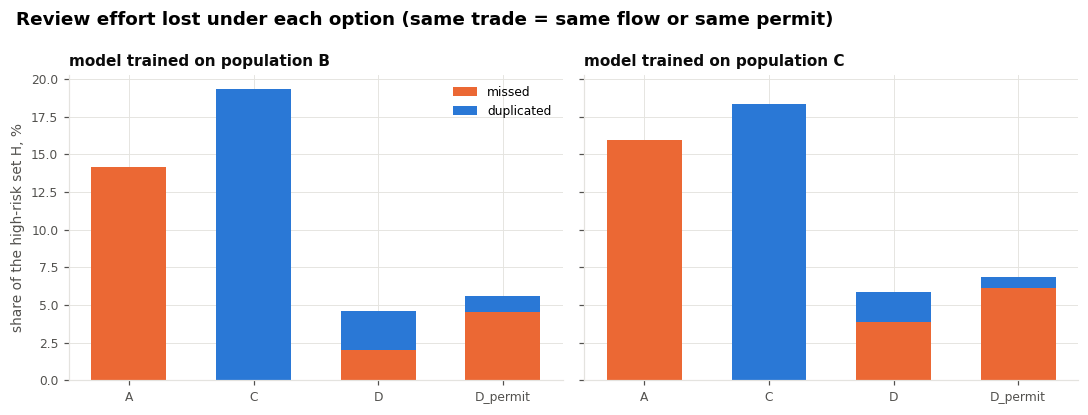

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
d = "... or same export permit"
labels = ["A", "C", "D", "D_permit"]
for ax, (m, c) in zip(axes, COSTS.items()):
    c = c.loc[d]
    ax.bar(labels, c["missed"] * 100, color=E.CITES_C, label="missed", width=0.6)
    ax.bar(labels, c["duplicated"] * 100, bottom=c["missed"] * 100, color=E.LEMIS_C,
           label="duplicated", width=0.6)
    ax.set_title(f"model trained on population {m}", loc="left", fontsize=10)
axes[0].set_ylabel("share of the high-risk set H, %")
axes[0].legend(frameon=False)
fig.suptitle("Review effort lost under each option (same trade = same flow or same permit)",
             x=0.02, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What option A would miss.** Importer-reported records in *H* whose trade has no exporter-reported record in *H* (same flow or same permit), by class and route:

In [17]:
f = flags("B")
f[~(f.flow_key | f.flow_permit)].groupby(["class", "exporter", "importer"]).size() \
    .sort_values(ascending=False).head(10).rename("missed_under_A").to_frame()

,,,missed_under_A
class,exporter,importer,
Bivalvia,TO,NZ,2079
Actinopteri,MY,GB,776
Anthozoa,CK,NZ,607
Bivalvia,CK,NZ,466
Actinopteri,MY,BR,416
Aves,MX,US,413
Actinopteri,MY,CA,375
Mammalia,MX,US,293
Reptilia,FR,AE,279


## 6. Do the two reports of one consignment disagree where the model sees risk?

For line items paired one-to-one on export permit and taxon: how often the two reports differ on quantity by more than 10%, among pairs the model ranks high (either report in *H*) and the rest. Comparing what the exporter and the importer reported is a common way of looking for irregular trade in CITES data. Without labels, this can only show whether it coincides with what the model, trained on LEMIS outcomes, considers risky.

In [18]:
Q("""SELECT CASE WHEN any_h THEN 'pair in H' ELSE 'pair not in H' END AS pairs,
            count(*) AS one_to_one_pairs,
            avg((abs(qe - qi) > 0.10 * greatest(qe, qi))::INT) AS share_disagreeing_over_10pct,
            avg((qi > 1.10 * qe)::INT) AS importer_reports_more,
            avg((qe > 1.10 * qi)::INT) AS exporter_reports_more
     FROM permit_groups WHERE ne = 1 AND ni = 1 AND qe > 0 AND qi > 0 GROUP BY 1 ORDER BY 1""")

,pairs,one_to_one_pairs,share_disagreeing_over_10pct,importer_reports_more,exporter_reports_more
0,pair in H,8185,0.1191,0.04166,0.07856
1,pair not in H,1607809,0.09888,0.02256,0.07934


## 7. Ranking permits instead of line items

LEMIS showed that enforcement outcomes are effectively shipment-level (notebook 01, L5). In CITES the closest equivalent of a shipment is the export permit. On the records chosen by rule D (model trained on population B), this section measures how a line-item queue treats permits:
- **duplicated consignments:** how many of the top-1% slots go to a second or later line of a permit already in the top 1%;
- **split consignments:** how often a permit that has a line in the top 1% also has lines below it, so the reviewer sees only part of the consignment.

Records without a permit ID count as their own permit.

In [19]:
con.register("queue_d", pd.DataFrame({"rid": X_.queue_rids(con, "D")}))
con.execute("""
    CREATE OR REPLACE TABLE q0 AS
    SELECT r.rid, r.year, r.score_B AS score, coalesce(r.export_permit, 'rid' || r.rid) AS permit
    FROM rec r JOIN queue_d USING (rid);
    CREATE OR REPLACE TABLE q AS
    SELECT *, row_number() OVER (PARTITION BY year ORDER BY score DESC) <=
              round(0.01 * count(*) OVER (PARTITION BY year)) AS top_line,
              row_number() OVER (PARTITION BY year, permit ORDER BY score DESC) AS rank_in_permit,
              count(*) OVER (PARTITION BY year, permit) AS permit_lines
    FROM q0;
""")
Q("""SELECT count(*) AS records, count(DISTINCT (year, permit)) AS permits,
            avg((permit_lines = 1)::INT) AS share_of_records_alone_on_their_permit,
            count(*) FILTER (WHERE top_line) AS top_1pct_slots,
            avg((rank_in_permit > 1)::INT) FILTER (WHERE top_line) AS share_of_slots_repeating_a_permit
     FROM q""")

,records,permits,share_of_records_alone_on_their_permit,top_1pct_slots,share_of_slots_repeating_a_permit
0,5465862,3239575,0.4638,54660,0.1334


In [20]:
Q("""WITH p AS (SELECT year, permit, count(*) AS lines, count(*) FILTER (WHERE top_line) AS in_top
            FROM q GROUP BY 1, 2 HAVING bool_or(top_line))
     SELECT count(*) AS permits_with_a_line_in_top_1pct,
            avg((lines > 1)::INT) AS share_with_several_lines,
            avg((in_top < lines)::INT) FILTER (WHERE lines > 1) AS of_those_split_across_the_cut,
            median(in_top / lines) FILTER (WHERE lines > 1) AS median_share_of_lines_in_top
     FROM p""")

,permits_with_a_line_in_top_1pct,share_with_several_lines,of_those_split_across_the_cut,median_share_of_lines_in_top
0,47370,0.1824,0.7312,0.5


## 8. Applying the decision rule

In [21]:
SIMPLER = list(OPTIONS)            # A, C, D, D_permit: the order of simplicity
first_rule = {m: c.loc["same year, taxon and countries"].drop(
                     "D_permit: + unmatched importer (field or permit match)") for m, c in COSTS.items()}


def choose(c):
    best = c["total"].min()
    return next(o for o in SIMPLER if o in c.index and c.loc[o, "total"] <= best + 0.01)


print("Option B admissible:", B_ADMISSIBLE)
print("\nFirst rule (field-value matching only, as in the first version):")
for m, c in first_rule.items():
    print(f"  model {m}: {choose(c)}")
d_better = all(c.loc[(d, "D_permit: + unmatched importer (field or permit match)"), "total"]
               <= c.loc[(d, "D: + unmatched importer (field match)"), "total"]
               for c in COSTS.values() for d in SAME_TRADE)
print(f"\nAddendum: D_permit's total cost is no higher than D's in every case: {d_better}")
print("Decision:", "D_permit (field or permit match)" if d_better else "D (field match)")

Option B admissible: {'field values': False, 'export permit + taxon': False}

First rule (field-value matching only, as in the first version):
  model B: D: + unmatched importer (field match)
  model C: D: + unmatched importer (field match)

Addendum: D_permit's total cost is no higher than D's in every case: False
Decision: D (field match)


Size of the review population under each rule (`experiment_setup.queue_rids`, which notebook 04 uses for its CITES checks):

In [22]:
pd.Series({r: len(X_.queue_rids(con, r)) for r in ["A", "C", "D", "D_permit"]},
          name="records scored").to_frame()

,records scored
A,4832710
C,8207319
D,5465862
D_permit,5129267


## What this means for Decision 1

These findings are from the rerun on the rebuilt data (see the note at the top). M1–M4 and M6 describe the data and did not change; M5 and M7–M9 depend on the model and were updated.

| # | Finding | What it means for Decision 1 |
|---|---|---|
| M1 | **Field values cannot pair the two reports.** 72% of exporter-reported records have an importer record with the same exact key, but only 0.8% have exactly one: a key usually covers many permits on each side | Matching on field values alone cannot merge a trade's two reports |
| M2 | **The export permit links them.** 94–99% of records each year carry an export permit ID. 1.47 million permits are reported by both countries, and the two sides agree on exporter (98.4%), importer (97.7%), year within one (99.5%) and at least one species (98.3%). Matched on permit and taxon, 49.5% of exporter records have a counterpart and 33.7% exactly one, and 89% of those pairs agree on quantity | Mirror records can be linked for about half of the trade. Merging pairs (option B) still fails the 90% test, so B remains inadmissible |
| M3 | **Permit numbering is often inconsistent.** Up to 25.6% of field-value pairs where both sides give a permit carry different permit IDs | A missing permit link does not prove that only one country reported the trade. Field matching is still needed alongside the permit |
| M4 | **For US imports, the importer's reports match what was actually traded better.** US-reported CITES records cover 76% of LEMIS line items of listed species; exporters' reports cover 62%, although there are more of them | Importer reports are not redundant copies of exporter reports |
| M5 | **Some trade is seen only by the importer.** 201,730 importer-reported records (6.0%) have no exporter record of the same trade by either link; for 58% of them the exporting country filed no export records that year. They are 7.6% of the high-risk set *H*, concentrated in flows such as Tonga → New Zealand (giant clams), Malaysia → United Kingdom (fish), Cook Islands → New Zealand and Mexico → US | Scoring exporter reports only (A) systematically hides exporters that do not report |
| M6 | **Some trade is seen only by the exporter.** 23% of exporter-reported records have no importer record by permit or exact key: 29% for Appendix I, 23% for II, 54% for III. The gap is concentrated by importing country: Taiwan 98% (not a CITES Party, so it files no reports), Russia 98%, Canada 96%, Singapore 50% | Whether an importer confirms a trade depends mostly on the importing country's reporting, not on the trade. "Not confirmed by the importer" cannot be read as a risk signal on its own |
| M7 | **Review effort lost** (share of *H*, model B; same trade = same flow / or same permit): A 14.7% / 14.2%; C 18.7% / 19.3%; **D 4.1% / 4.6%**; D_permit 6.2% / 5.6%. With model C: A 16.4 / 16.0; C 17.9 / 18.3; **D 5.4 / 5.9**; D_permit 7.3 / 6.9. Using the permit to drop importer reports (D_permit) cuts duplication but misses more (5.1% of *H* against D's 2.0%, model B, same flow), because the two reports of one permit often get different scores and the dropped one is the flagged one | D has the lowest cost in all four cases (three of four in the first run), and the addendum (D_permit must be no worse in every case) keeps D. The permit should not be used to drop records |
| M8 | **The two reports of one consignment disagree only slightly more where the model sees risk.** Among one-to-one permit pairs, quantities differ by more than 10% in 11.9% of pairs in *H* and 9.9% of the rest; the importer reports more in 4.2% against 2.3%. The first run found 33.3% against 9.8% | The strong link of the first run largely disappears with the rebuilt data, the chosen model settings and LEMIS norms; the rerun did not test which change removed it. Showing the reviewer both reports remains useful context. Using disagreement as a learned feature is not possible (LEMIS has no permits) |
| M9 | **A line-item queue splits and repeats consignments.** Under D, 5,465,862 records sit on 3,239,575 permits; 46% of records are alone on their permit. 13.3% of top-1% slots go to a second or later line of a permit already in the top 1%, including the other country's report of the same consignment. Of the 47,370 permits with a line in the top 1%, 18.2% have several lines, and 73% of those are split across the cut (median: half the lines in the top 1%) | Ranking by permit frees about one top-1% slot in eight and shows whole consignments. Decided: the queue ranks permits, each scored by its highest record (DESIGN_QUESTIONS S6.1, notebook 14). The counts here key a permit on its ID alone; the queue also keys it on exporter, importer and year, because the anonymised IDs occur on unrelated trades (S6.1, corrected 31 October 2026) |

**Under the decision rule the result is D:** score exporter-reported records, plus importer-reported records with no exact exporter counterpart on field values.
- Pairing (B) fails the admissibility test with either link.
- D has the lowest cost in all four cases.
- The permit-based variant (D_permit) does not meet the addendum's condition.
- The decision is the same with either training population.

**What the permit is used for instead:**
- grouping records into consignments for review (M9);
- showing both countries' reports of a consignment side by side (M8).

**What follows:**
- **Aggregate statistics** use exporter-reported records only.
- **The review tool's unit:** permits, decided in DESIGN_QUESTIONS S6.1 (notebook 14).
- **Peer norms for the CITES features:** the first run proposed learning them from the D population. Notebook 08 (S2.1) found CITES-learned norms significantly worse on two of six held-out LEMIS populations, so CITES records are described with LEMIS norms.
- **A limitation.** LEMIS has no permit IDs, so nothing that depends on permits can be learned from enforcement outcomes: mirror disagreement, one-sided reporting, items sharing a permit, and re-export chains through origin permits. These can enter only as context or unsupervised evidence.

**Limits of this experiment:**
- *H* comes from one model per training population, and missed and duplicated slots are weighted equally.
- "Same trade" is matched on keys and permits that are themselves imperfect (M3).
- The fidelity comparison (M4) covers one importing country.
- The addendum was written after the first run, though before any permit result was seen.